# CrashMap France - exploration des données (2019-2024)

Ce notebook explore les données nettoyées par `python run.py clean` (fichiers `data/processed/*.parquet`)
et illustre les principales étapes : structure des 4 fichiers, piège du double comptage, valeurs manquantes,
gravité selon l'heure, les conditions et les usagers. Les fonctions viennent du package `src/crashmap`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

from crashmap import analyze, codebook

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "reports" / "figures"


## 1. Les trois grains

In [2]:
accidents = pd.read_parquet(PROCESSED / "accidents.parquet")
vehicles = pd.read_parquet(PROCESSED / "vehicles.parquet")
victims = pd.read_parquet(PROCESSED / "victims.parquet")
pd.DataFrame({
    "lignes": [len(accidents), len(vehicles), len(victims)],
    "colonnes": [accidents.shape[1], vehicles.shape[1], victims.shape[1]],
    "clé": ["accident_id", "vehicle_key", "victim_id"],
}, index=["accidents", "véhicules", "victimes (personnes)"])

,lignes,colonnes,clé
accidents,327628,72,accident_id
véhicules,559847,30,vehicle_key
victimes (personnes),745158,43,victim_id


In [3]:
accidents.groupby("year").agg(accidents=("accident_id", "size"), tues=("n_killed", "sum"),
                             vehicules=("n_vehicles", "sum"), usagers=("n_users", "sum"))

,accidents,tues,vehicules,usagers
year,,,,
2019,58840,3498,100710,132977
2020,47744,2780,81066,105295
2021,56518,3219,97315,129248
2022,55302,3550,94493,126662
2023,54822,3398,93585,125789
2024,54402,3432,92678,125187


## 2. Le piège du double comptage

Joindre accidents, véhicules et usagers donne une ligne **par personne**. Compter les lignes de cette
jointure surestime le nombre d'accidents ; sommer `n_killed` sur cette jointure multiplie les tués.

In [4]:
joined = (accidents[["accident_id", "n_killed"]]
          .merge(vehicles[["accident_id", "vehicle_key"]], on="accident_id")
          .merge(victims[["vehicle_key", "killed"]], on="vehicle_key"))
pd.Series({
    "accidents (grain accident)": len(accidents),
    "lignes de la jointure": len(joined),
    "accidents distincts dans la jointure": joined["accident_id"].nunique(),
    "tués (grain accident)": int(accidents["n_killed"].sum()),
    "SUM(n_killed) sur la jointure (faux)": int(joined["n_killed"].sum()),
    "tués (grain victime)": int(victims["killed"].sum()),
})

accidents (grain accident)              327628
lignes de la jointure                   745158
accidents distincts dans la jointure    327628
tués (grain accident)                    19877
SUM(n_killed) sur la jointure (faux)     47118
tués (grain victime)                     19877
dtype: int64

## 3. Valeurs manquantes (après conversion des codes -1 / 0 « non renseigné » en nul)

In [5]:
cols = ["lum", "atm", "surf", "col", "catr", "vma", "int", "plan", "lat"]
(accidents[cols].isna().mean() * 100).round(2).rename("% manquant").to_frame().T

,lum,atm,surf,col,catr,vma,int,plan,lat
% manquant,0.0,0.01,0.02,0.49,0.0,1.7,0.0,0.01,0.01


In [6]:
(victims[["grav", "sexe", "age", "trajet", "secu1", "seatbelt_worn"]].isna().mean() * 100).round(2).rename("% manquant").to_frame().T

,grav,sexe,age,trajet,secu1,seatbelt_worn
% manquant,0.06,1.43,1.52,27.76,1.34,6.13


In [7]:
accidents["coord_status"].value_counts().to_frame("accidents")

,accidents
coord_status,
valide,327580
hors zone,48


## 4. Quand ? Heure et jour

In [8]:
acc = analyze.add_analysis_labels(accidents)
analyze.rate_table(acc, "time_band")

,time_band,n_accidents,n_killed,n_fatal,killed_per_100,pct_fatal,pct_fatal_ci_low,pct_fatal_ci_high
0,Journée (10h-17h),126407,7007,6641,5.54,5.25,5.13,5.38
1,Matin (6h-10h),56802,3030,2888,5.33,5.08,4.91,5.27
2,Nuit (21h-6h),53914,5195,4783,9.64,8.87,8.63,9.11
3,Soirée (17h-21h),90505,4645,4386,5.13,4.85,4.71,4.99


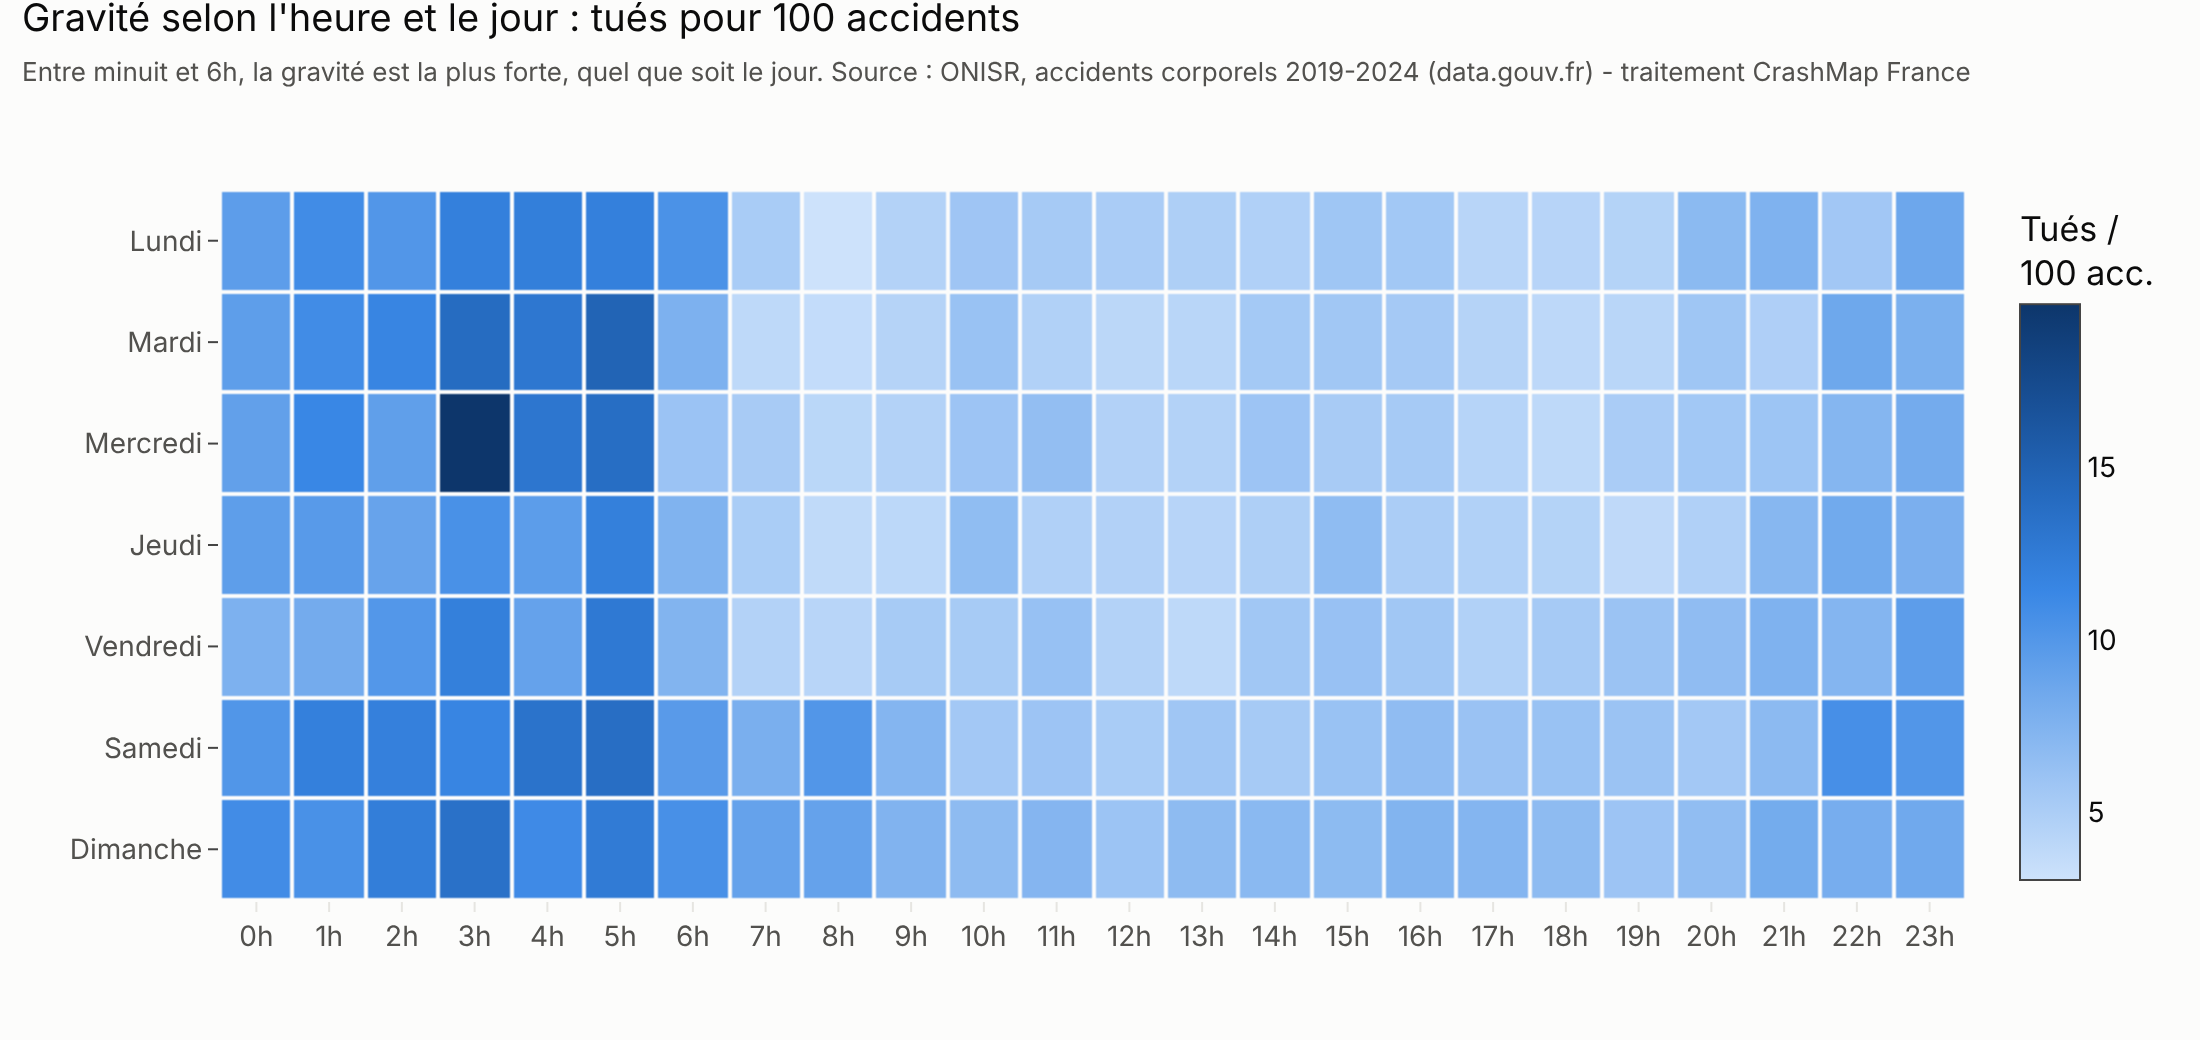

In [9]:
display(Image(FIGURES / "fig02_hour_weekday_heatmap.png", width=900))

## 5. Où ? En agglomération ou non, catégorie de route

In [10]:
analyze.rate_table(acc, "in_town_label")

,in_town_label,n_accidents,n_killed,n_fatal,killed_per_100,pct_fatal,pct_fatal_ci_low,pct_fatal_ci_high
0,En agglomération,208478,6502,6275,3.12,3.01,2.94,3.08
1,Hors agglomération,119150,13375,12423,11.23,10.43,10.25,10.60


In [11]:
analyze.rate_table(acc, "catr_label").sort_values("killed_per_100", ascending=False)

,catr_label,n_accidents,n_killed,n_fatal,killed_per_100,pct_fatal,pct_fatal_ci_low,pct_fatal_ci_high
6,Route nationale,21134,2047,1854,9.69,8.77,8.40,9.16
5,Route départementale,122714,11558,10863,9.42,8.85,8.69,9.01
2,Hors réseau public,397,34,33,8.56,8.31,5.98,11.44
1,Autre,1977,134,123,6.78,6.22,5.24,7.37
4,Route de métropole urbaine,9797,529,496,5.40,5.06,4.65,5.51
0,Autoroute,30949,1562,1414,5.05,4.57,4.34,4.81
3,Parc de stationnement ouvert à la circulation ...,2412,120,118,4.98,4.89,4.10,5.83
7,Voie communale,138248,3893,3797,2.82,2.75,2.66,2.83


## 6. Dans quelles conditions ? Khi-deux et V de Cramér

In [12]:
analyze.chi_square_tests(acc)[["label", "n", "levels", "chi2", "p_value", "cramers_v"]]

,label,n,levels,chi2,p_value,cramers_v
0,Vitesse maximale autorisée,322057,6,8539.2,0.000000e+00,0.1628
1,Localisation,327628,2,7749.5,0.000000e+00,0.1538
2,Type de collision,326009,7,5828.0,0.000000e+00,0.1337
3,Catégorie de route,327628,8,4967.6,0.000000e+00,0.1231
4,Luminosité,327619,5,4513.4,0.000000e+00,0.1174
5,Nombre de véhicules,327628,3,2727.6,0.000000e+00,0.0912
6,Type d'intersection,327614,9,2565.1,0.000000e+00,0.0885
7,Tracé,327585,4,1546.8,0.000000e+00,0.0687
8,Deux-roues ou EDP impliqué,327628,2,1269.4,4.940169e-278,0.0622
9,Tranche horaire,327628,4,1217.1,1.407853e-263,0.0610


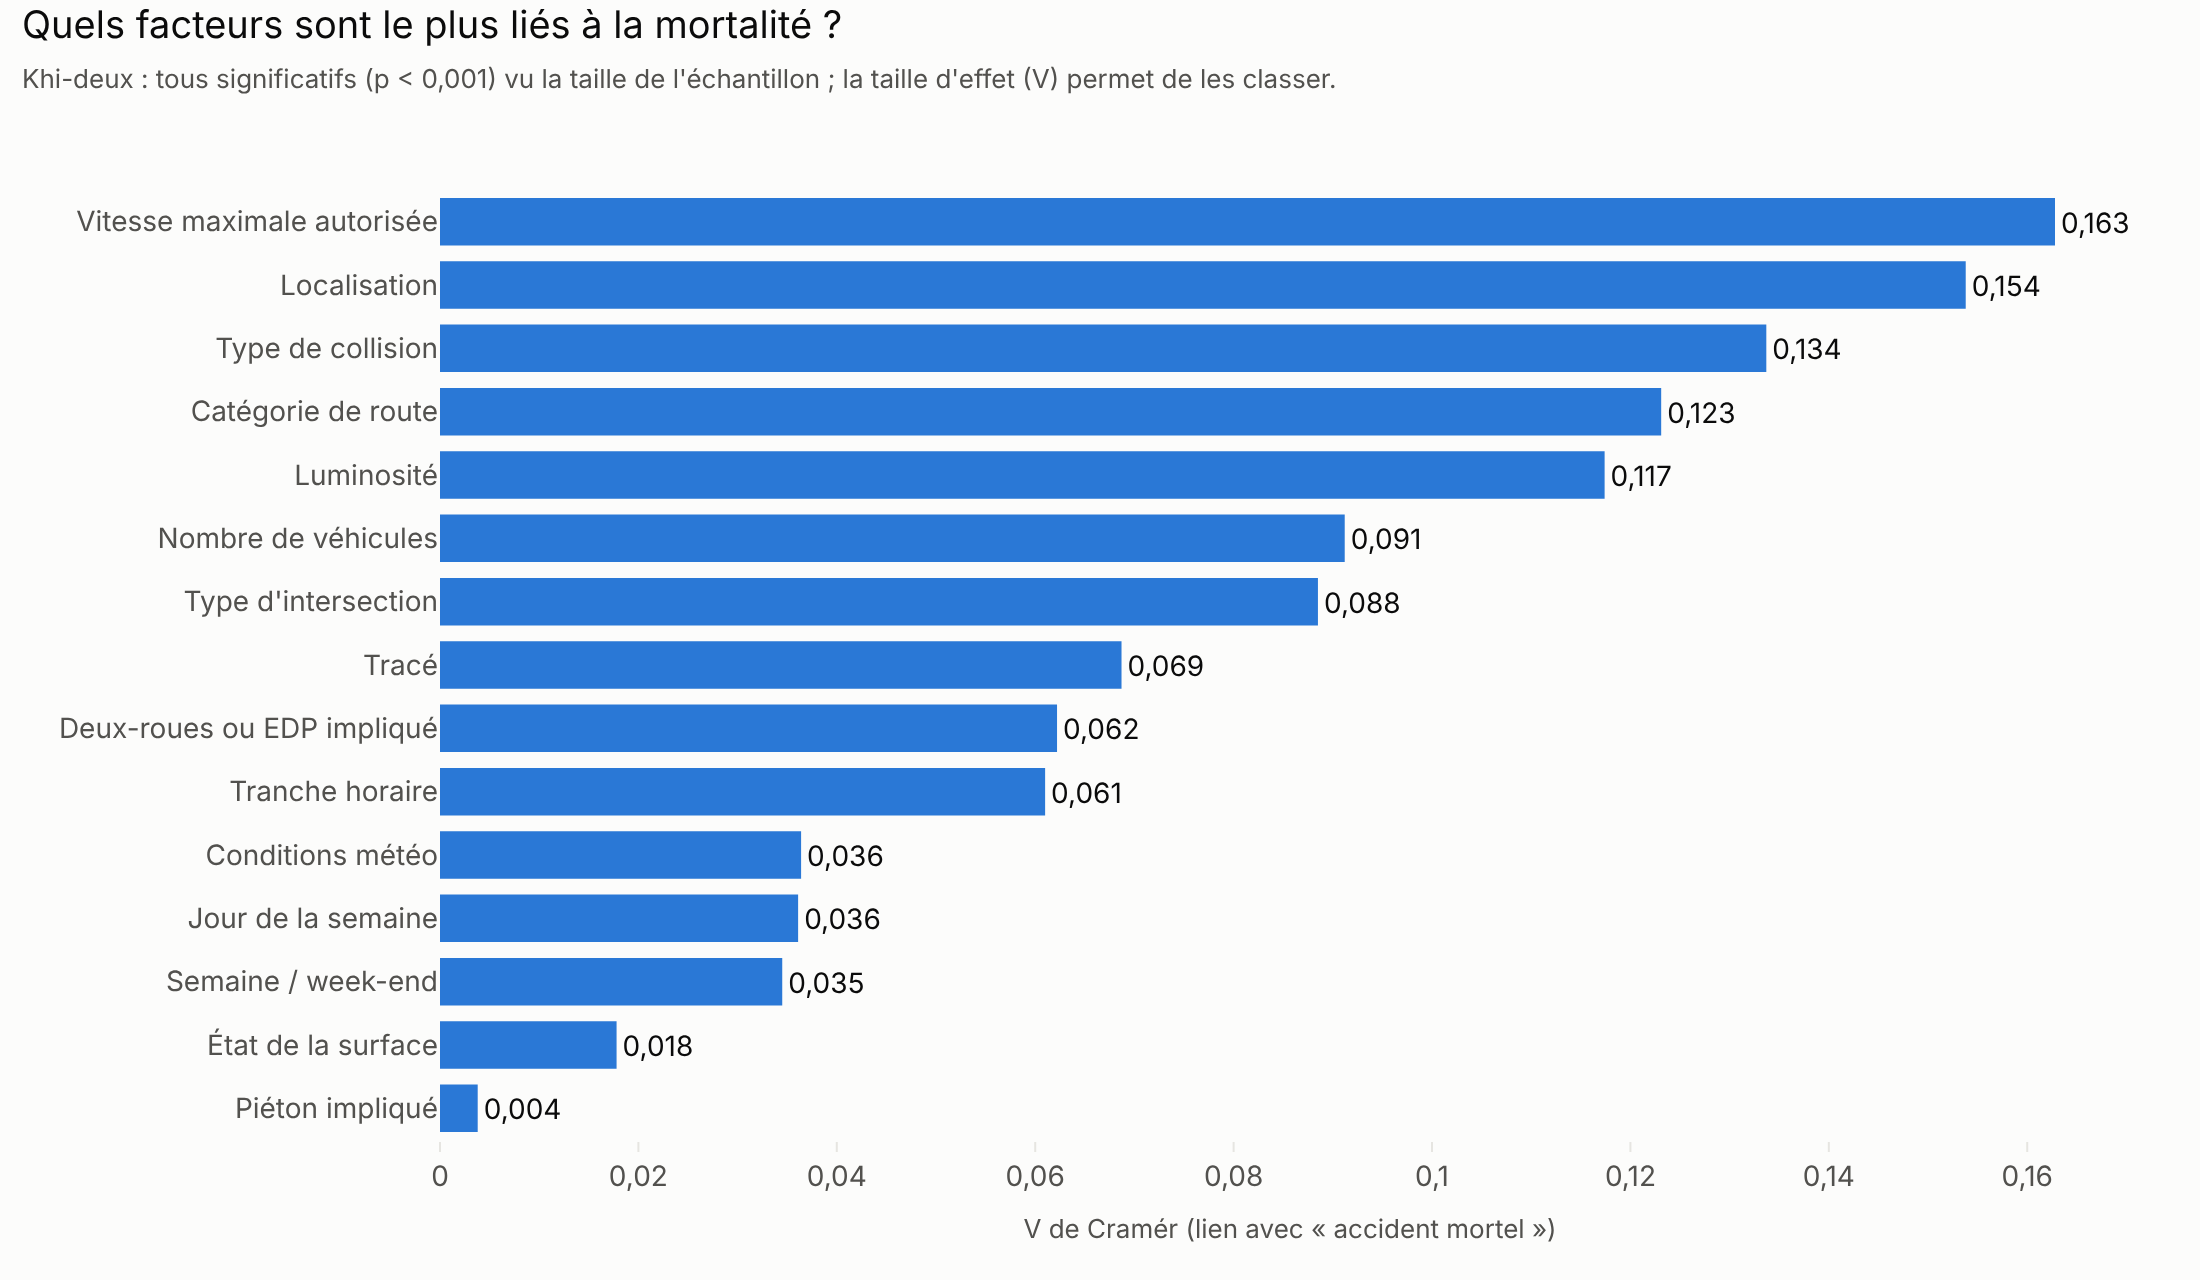

In [13]:
display(Image(FIGURES / "fig06_cramers_v.png", width=850))

## 7. Qui ? Mode de déplacement, âge, équipement

In [14]:
analyze.victim_tables(victims)["victims_by_mode"].head(10)

,user_mode,n_persons,n_killed,n_accidents,pct_killed,pct_killed_ci_low,pct_killed_ci_high,n_killed_or_hosp,pct_killed_or_hosp
13,Voiture (VL),430158,9415,244281,2.19,2.15,2.23,53714,12.49
7,Moto > 125 cm3,59254,3173,52252,5.35,5.18,5.54,23713,40.02
8,Piéton,57510,2928,53430,5.09,4.91,5.27,18899,32.86
15,Vélo (y.c. VAE),34659,1356,32829,3.91,3.71,4.12,9631,27.79
2,Cyclomoteur <= 50 cm3,40843,847,35519,2.07,1.94,2.22,12049,29.50
12,Utilitaire (VU),46807,699,36181,1.49,1.39,1.61,3584,7.66
6,Moto 50-125 cm3,24335,630,22050,2.59,2.40,2.80,6891,28.32
9,Poids lourd,16715,245,14766,1.47,1.29,1.66,1097,6.56
3,EDP motorisé (trottinette...),10930,169,10248,1.55,1.33,1.80,1872,17.13
14,Voiturette,4038,139,3025,3.44,2.92,4.05,708,17.53


In [15]:
analyze.equipment_table(victims)[["group", "equipment", "worn", "n_persons", "pct_killed", "pct_killed_ci_low", "pct_killed_ci_high", "relative_risk_killed_not_worn"]]

,group,equipment,worn,n_persons,pct_killed,pct_killed_ci_low,pct_killed_ci_high,relative_risk_killed_not_worn
0,Conducteurs de voiture,Ceinture,Porté,284245,1.70,1.66,1.75,4.09
1,Conducteurs de voiture,Ceinture,Non porté,19084,6.95,6.60,7.32,4.09
2,Passagers de voiture,Ceinture,Porté,87780,1.50,1.42,1.58,3.81
3,Passagers de voiture,Ceinture,Non porté,11713,5.72,5.31,6.16,3.81
4,Conducteurs de moto > 125 cm3,Casque,Porté,51454,5.53,5.34,5.73,1.41
5,Conducteurs de moto > 125 cm3,Casque,Non porté,1527,7.79,6.55,9.25,1.41
6,Conducteurs de moto 50-125 cm3,Casque,Porté,20601,2.54,2.33,2.76,2.33
7,Conducteurs de moto 50-125 cm3,Casque,Non porté,1147,5.93,4.70,7.45,2.33
8,Conducteurs de cyclomoteur,Casque,Porté,32985,2.06,1.92,2.22,2.17
9,Conducteurs de cyclomoteur,Casque,Non porté,2076,4.48,3.67,5.46,2.17


## 8. Facteurs de gravité (régression logistique)

Résultats produits par `src/crashmap/model.py` (rapports de cotes à autres facteurs égaux).

In [16]:
pd.read_csv(ROOT / "reports" / "tables" / "odds_ratios.csv").head(12)

,variable,variable_label,level,reference,n_accidents,odds_ratio,ci_low,ci_high,p_value
0,speed,Vitesse maximale autorisée,130 km/h,40-50 km/h,6211,6.339,5.575,7.209,1.976475e-174
1,intersection,Intersection,Passage à niveau,Hors intersection,640,4.699,3.772,5.854,2.329182e-43
2,speed,Vitesse maximale autorisée,80-90 km/h,40-50 km/h,71316,1.945,1.819,2.081,2.200661e-83
3,location,Localisation,Hors agglomération,En agglomération,116202,1.910,1.789,2.039,1.173097e-83
4,light,Luminosité,Nuit avec éclairage public non allumé,Plein jour,3163,1.780,1.552,2.041,1.483039e-16
5,speed,Vitesse maximale autorisée,100-110 km/h,40-50 km/h,11546,1.761,1.588,1.954,1.026602e-26
6,road,Catégorie de route,Route départementale,Voie communale,119976,1.715,1.637,1.796,9.793394e-115
7,vehicles,Nombre de véhicules,1 véhicule,2 véhicules,122015,1.672,1.610,1.736,4.665751e-158
8,speed,Vitesse maximale autorisée,60-70 km/h,40-50 km/h,24314,1.582,1.472,1.701,2.499457e-35
9,light,Luminosité,Nuit sans éclairage public,Plein jour,32589,1.449,1.364,1.539,3.263812e-33


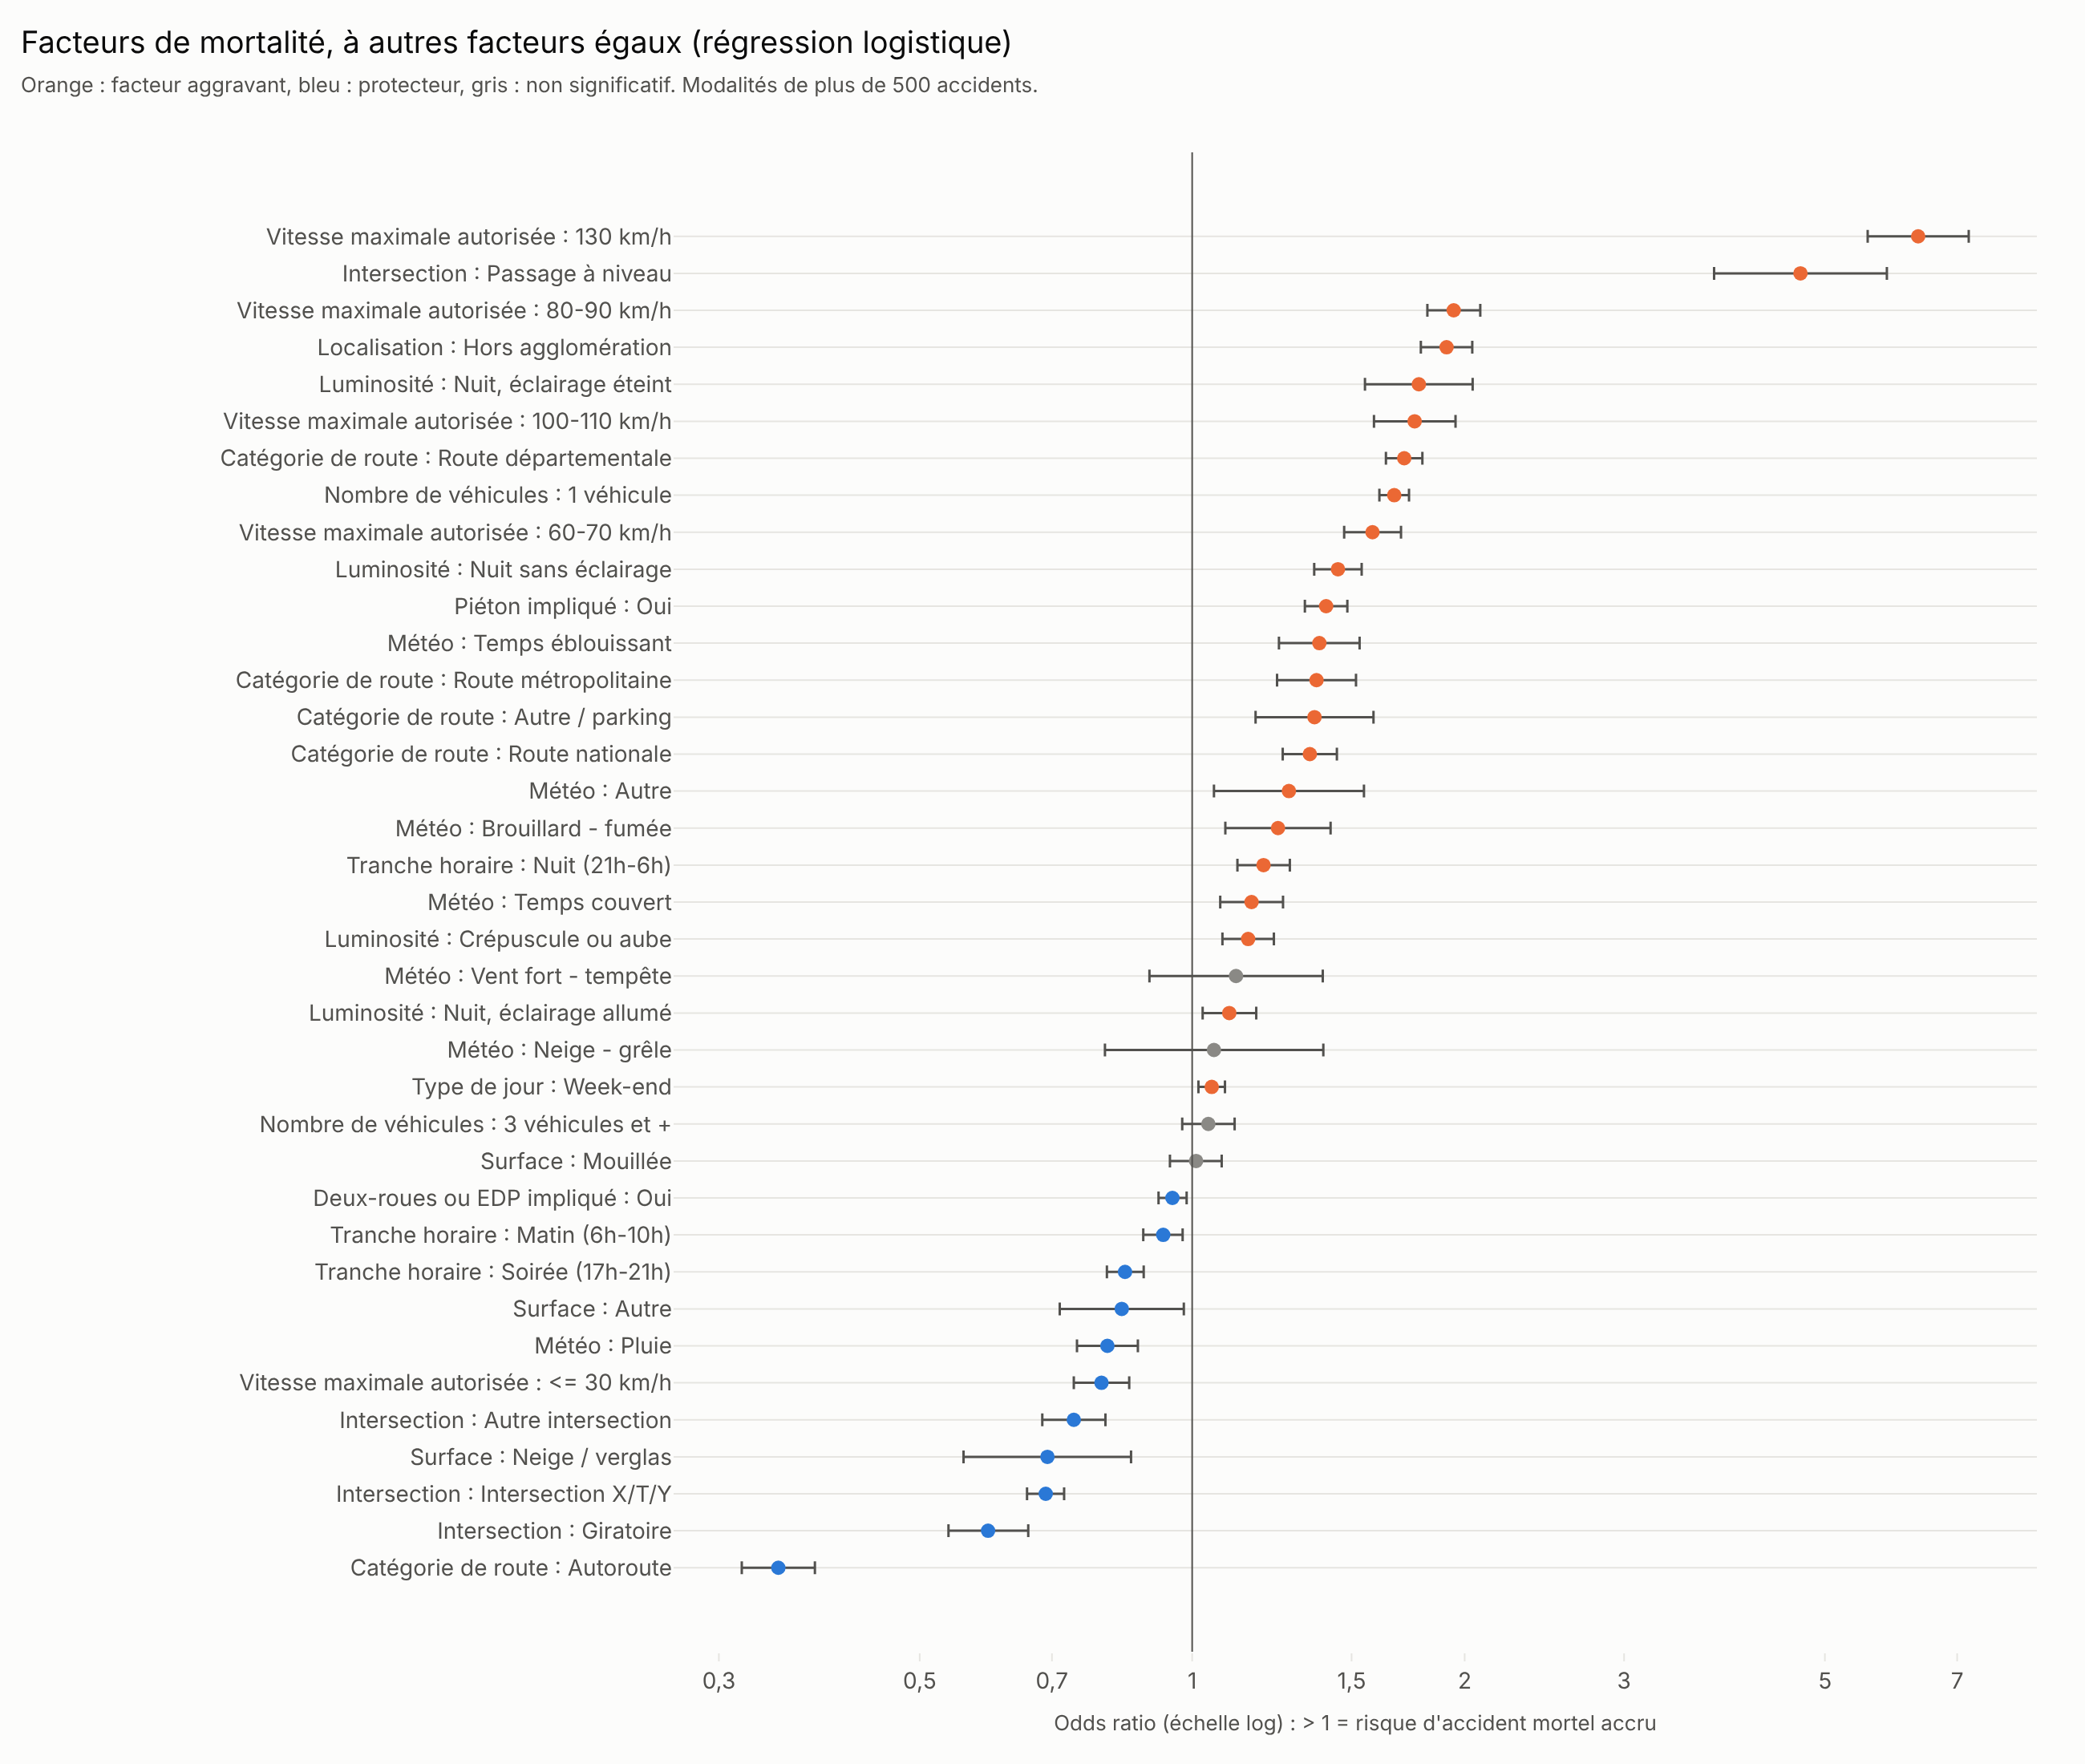

In [17]:
display(Image(FIGURES / "fig07_odds_ratios.png", width=850))

## 9. Évolution 2019-2024 (2020 = anomalie COVID)

In [18]:
analyze.trend_tables(accidents, victims)["trend_yearly"]

,year,n_accidents,n_killed,n_fatal,n_hospitalized,killed_per_100,pct_change_killed_vs_first_year,pct_change_accidents_vs_first_year,covid_year
0,2019,58840,3498,3284,20858,5.94,0.0,0.0,False
1,2020,47744,2780,2616,16775,5.82,-20.5,-18.9,True
2,2021,56518,3219,3032,19093,5.70,-8.0,-3.9,False
3,2022,55302,3550,3337,19260,6.42,1.5,-6.0,False
4,2023,54822,3398,3203,19271,6.20,-2.9,-6.8,False
5,2024,54402,3432,3226,19126,6.31,-1.9,-7.5,False


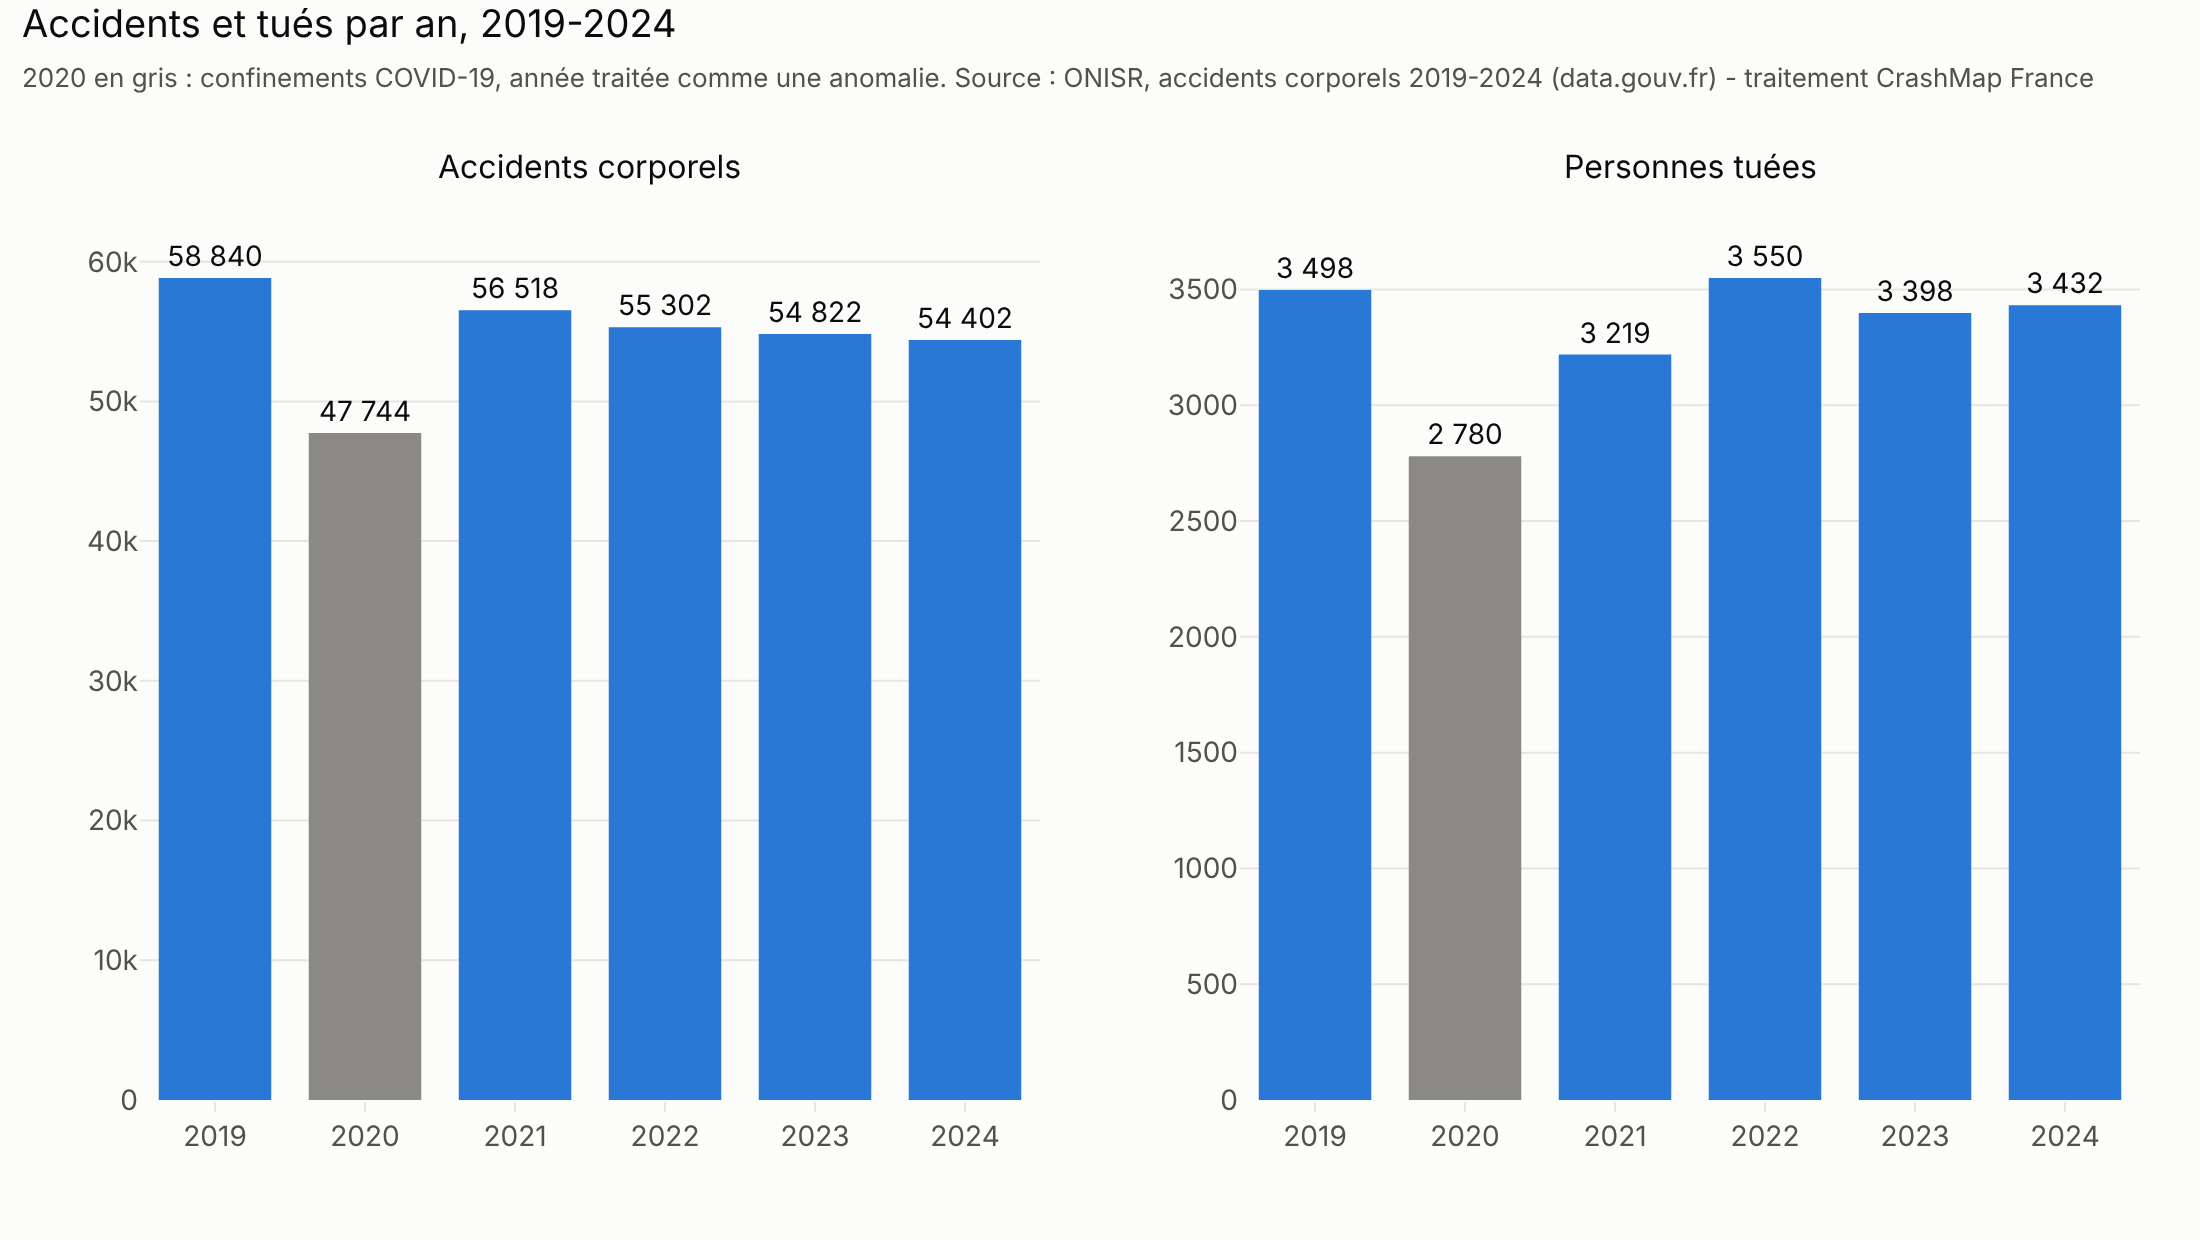

In [19]:
display(Image(FIGURES / "fig01_trend_yearly.png", width=900))